## 统计分析

通过指定统计分析字段，得到每个特征的p_value，所有的p_value计算都是基于Ttest计算。支持指定不同的分组`group`，例如train、val、test等分组统计。

对于两大类不同的特征

1. 离散特征，统计数量以及占比。
2. 连续特征，统计均值、方差。

In [1]:
import pandas as pd
import numpy as np
from onekey_algo import OnekeyDS as okds
from onekey_algo import get_param_in_cwd
from onekey_algo.custom.utils import print_join_info

task = get_param_in_cwd('task_column') or 'label'
p_value = get_param_in_cwd('p_value') or 0.05
# 修改成自己临床数据的文件。
test_data = pd.read_csv(get_param_in_cwd('clinic_file'))
stats_columns_settings = get_param_in_cwd('stats_columns')
continuous_columns_settings = get_param_in_cwd('continuous_columns')
mapping_columns_settings = get_param_in_cwd('mapping_columns')
test_data = test_data[[c for c in test_data.columns if c != task]]
test_data['ID'] = test_data['ID'].map(lambda x: f"{x}.nii.gz" if not (f"{x}".endswith('.nii.gz') or  f"{x}".endswith('.nii')) else x)
group_info = pd.read_csv(get_param_in_cwd('label_file'))
print_join_info(test_data, group_info)
test_data = pd.merge(test_data, group_info, on='ID', how='inner')
test_data

[2026-07-10 10:05:35 - <frozen onekey_algo.custom.utils>:  60]	INFO	ID特征完全匹配！


,ID,age,Gender,Alcohol,Smoking,location,T_stage,KI_grade,differentiation,LN MAX minor axis,label,group
0,1.nii.gz,54,0,0,1,2,3,3,2,12.82,0,train
1,2.nii.gz,67,0,0,0,1,3,1,1,13.81,0,train
2,3.nii.gz,67,0,0,0,2,1,3,3,10.48,0,train
3,4.nii.gz,62,0,0,0,1,4,2,1,8.84,0,train
4,5.nii.gz,73,0,0,1,3,1,3,2,8.77,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...
468,642.nii.gz,62,0,1,1,1,2,1,2,16.85,1,test2
469,643.nii.gz,66,0,1,1,1,3,2,1,8.30,1,test2
470,644.nii.gz,51,0,1,0,1,3,1,3,4.37,1,test2
471,645.nii.gz,73,0,1,0,1,4,1,2,6.35,1,test2


# 特征名称处理

去掉所有特征名称中的特殊字符。

In [2]:
import re

def map_cnames(x):
    x = re.split('[（|(]', x)[0]
    x = x.replace('-', '_').replace(' ', '_').replace('>', '').replace('/', '_')
    return x.strip()

test_data.columns = list(map(map_cnames, test_data.columns))
test_data.columns

Index(['ID', 'age', 'Gender', 'Alcohol', 'Smoking', 'location', 'T_stage',
       'KI_grade', 'differentiation', 'LN_MAX_minor_axis', 'label', 'group'],
      dtype='object')

# 分析数据

获取待分析的特征列名，如未制定，自动侦测。

In [3]:
stats_columns = stats_columns_settings or list(test_data.columns[1:-2])
test_data = test_data.copy()[['ID'] + stats_columns + ['group', 'label']]
test_data

,ID,age,Gender,Alcohol,Smoking,location,T_stage,KI_grade,differentiation,LN_MAX_minor_axis,group,label
0,1.nii.gz,54,0,0,1,2,3,3,2,12.82,train,0
1,2.nii.gz,67,0,0,0,1,3,1,1,13.81,train,0
2,3.nii.gz,67,0,0,0,2,1,3,3,10.48,train,0
3,4.nii.gz,62,0,0,0,1,4,2,1,8.84,train,0
4,5.nii.gz,73,0,0,1,3,1,3,2,8.77,train,0
...,...,...,...,...,...,...,...,...,...,...,...,...
468,642.nii.gz,62,0,1,1,1,2,1,2,16.85,test2,1
469,643.nii.gz,66,0,1,1,1,3,2,1,8.30,test2,1
470,644.nii.gz,51,0,1,0,1,3,1,3,4.37,test2,1
471,645.nii.gz,73,0,1,0,1,4,1,2,6.35,test2,1


# 特征队列映射

所有需要进行特征映射的队列，range未制定，可以进行自动判断。

In [4]:
mapping_columns = mapping_columns_settings or [c for c in test_data.columns[1:-2] if test_data[c].dtype == object]
mapping_columns

[]

# 数据映射

针对所有非数值形式的数据，可以进行类别映射。

In [5]:
from onekey_algo.custom.utils import map2numerical

data, mapping = map2numerical(test_data, mapping_columns=mapping_columns)
mapping

{}

In [6]:
from onekey_algo.custom.components.comp1 import fillna

data = fillna(data, fill_mod='50%')
continuous_columns = []
for col in test_data.columns:
    if test_data[col].apply(lambda x: x.is_integer() if isinstance(x, float) else False).all():
        test_data[col] = test_data[col].astype(int)

for c in stats_columns:
#     print(c, np.unique(test_data[c]), test_data[c].dtype)
    if len(np.unique(test_data[c])) > 5 or not np.int8 <= test_data[c].dtype <= np.int64:
        continuous_columns.append(c)
        
continuous_columns = continuous_columns_settings or continuous_columns
continuous_columns = [c for c in continuous_columns if c not in ('differentation')]
continuous_columns

['age', 'LN_MAX_minor_axis']

# 缺失值填充

In [7]:
import os
os.makedirs('data', exist_ok=True)
data.to_csv('data/clinical.csv', index=False)
data

,ID,age,Gender,Alcohol,Smoking,location,T_stage,KI_grade,differentiation,LN_MAX_minor_axis,group,label
0,1.nii.gz,54,0,0,1,2,3,3,2,12.82,train,0
1,2.nii.gz,67,0,0,0,1,3,1,1,13.81,train,0
2,3.nii.gz,67,0,0,0,2,1,3,3,10.48,train,0
3,4.nii.gz,62,0,0,0,1,4,2,1,8.84,train,0
4,5.nii.gz,73,0,0,1,3,1,3,2,8.77,train,0
...,...,...,...,...,...,...,...,...,...,...,...,...
468,642.nii.gz,62,0,1,1,1,2,1,2,16.85,test2,1
469,643.nii.gz,66,0,1,1,1,3,2,1,8.30,test2,1
470,644.nii.gz,51,0,1,0,1,3,1,3,4.37,test2,1
471,645.nii.gz,73,0,1,0,1,4,1,2,6.35,test2,1


### 统计分析

支持两种格式数据，分别对应`pretty`参数的`True`和`False`, 当为`True`时，输出的是表格模式，反之则为dict数据。

```python
def clinic_stats(data: DataFrame, stats_columns: Union[str, List[str]], label_column='label',
                 group_column: str = None, continuous_columns: Union[str, List[str]] = None,
                 pretty: bool = True) -> Union[dict, DataFrame]:
    """

    Args:
        data: 数据
        stats_columns: 需要统计的列名
        label_column: 二分类的标签列，默认`label`
        group_column: 分组统计依据，例如区分训练组、测试组、验证组。
        continuous_columns: 那些列是连续变量，连续变量统计均值方差。
        pretty: bool, 是否对结果进行格式美化。

    Returns:
        stats DataFrame or json

    """
```

In [8]:
from onekey_algo.custom.components.stats import clinic_stats

pd.set_option('display.max_rows', None)
stats = clinic_stats(data, 
                     stats_columns= stats_columns,
                     label_column=task, 
                     group_column='group', 
                     continuous_columns= continuous_columns, 
                     pretty=True, verbose=False)
stats.to_csv(f'data/stats_{task}.csv', index=False, encoding='utf_8_sig')
stats

,feature_name,test1-label=ALL,test1-label=0,test1-label=1,pvalue,test2-label=ALL,test2-label=0,test2-label=1,pvalue,train-label=ALL,train-label=0,train-label=1,pvalue
0,age,61.30±7.69,61.98±7.65,59.88±7.65,0.091,63.19±8.72,63.86±7.93,62.16±9.84,0.394,62.72±8.68,62.60±8.49,63.03±9.20,0.739
1,LN_MAX_minor_axis,13.04±5.44,10.58±3.93,18.22±4.47,<0.001,4.74±3.65,3.25±2.56,7.01±3.94,<0.001,9.78±3.51,9.26±3.21,11.09±3.89,<0.001
0,Gender,,,,0.136,,,,1.0,,,,0.799
1,0,166(95.40),115(97.46),51(91.07),,77(95.06),47(95.92),30(93.75),,207(94.95),149(95.51),58(93.55),
2,1,8(4.60),3(2.54),5(8.93),,4(4.94),2(4.08),2(6.25),,11(5.05),7(4.49),4(6.45),
3,Alcohol,,,,0.413,,,,0.008,,,,0.292
4,0,125(71.84),82(69.49),43(76.79),,28(34.57),23(46.94),5(15.62),,123(56.42),92(58.97),31(50.00),
5,1,49(28.16),36(30.51),13(23.21),,53(65.43),26(53.06),27(84.38),,95(43.58),64(41.03),31(50.00),
6,Smoking,,,,0.098,,,,0.149,,,,0.109
7,0,61(35.06),36(30.51),25(44.64),,29(35.80),14(28.57),15(46.88),,53(24.31),43(27.56),10(16.13),


In [9]:
from onekey_algo.custom.components.stats import clinic_stats

pd.set_option('display.max_rows', None)
stats = clinic_stats(data, 
                     stats_columns= stats_columns,
                     label_column='group', 
                     group_column=None, 
                     continuous_columns= continuous_columns, 
                     pretty=True, verbose=False)
stats.to_csv('data/statics.csv', index=False, encoding='utf_8_sig')
stats

,feature_name,-label=ALL,-label=test1,-label=test2,-label=train,pvalue
0,age,62.28±8.35,61.30±7.69,63.19±8.72,62.72±8.68,0.14
1,LN_MAX_minor_axis,10.12±5.19,13.04±5.44,4.74±3.65,9.78±3.51,<0.001
2,Gender,,,,,0.979
3,0,450(95.14),166(95.40),77(95.06),207(94.95),
4,1,23(4.86),8(4.60),4(4.94),11(5.05),
5,Alcohol,,,,,<0.001
6,0,276(58.35),125(71.84),28(34.57),123(56.42),
7,1,197(41.65),49(28.16),53(65.43),95(43.58),
8,Smoking,,,,,0.034
9,0,143(30.23),61(35.06),29(35.80),53(24.31),


# 单因素多因素分析

单因素，步进多因素分析
```python
def uni_multi_variable_analysis(data: pd.DataFrame, features: Union[str, List[str]] = None, label_column: str = 'label',
                                need_norm: Union[bool, List[bool]] = False, alpha=0.1,
                                p_value4multi: float = 0.05, save_dir: Union[str] = None, prefix: str = '',
                                **kwargs):
    """
    单因素，步进多因素分析，使用p_value4multi参数指定多因素分析的阈值
    Args:
        data: 数据
        features: 需要分析的特征，默认除了ID和label_column列，其他的特征都进行分析。
        label_column: 目标列
        need_norm: 是否标准化所有分析的数据, 默认为False
        alpha: CI alpha, alpha/2 %；默认为0.1即95% CI
        p_value4multi: 参数指定多因素分析的阈值，默认为0.05
        save_dir: 保存位置
        prefix: 前缀
        **kwargs:

    Returns:

    """
 ```

,Log(OR),lower 95%CI,upper 95%CI,OR,OR lower 95%CI,OR upper 95%CI,p_value
feature_name,,,,,,,
age,-0.014,-0.018,-0.010,0.986,0.982,0.990,0.000
Gender,-0.560,-1.591,0.471,0.571,0.204,1.602,0.372
Alcohol,-0.725,-1.085,-0.365,0.484,0.338,0.694,0.001
Smoking,-0.776,-1.052,-0.501,0.460,0.349,0.606,0.000
location,-0.490,-0.620,-0.360,0.613,0.538,0.698,0.000
T_stage,-0.198,-0.298,-0.099,0.820,0.742,0.906,0.001
KI_grade,-0.398,-0.522,-0.275,0.672,0.593,0.760,0.000
differentiation,-0.415,-0.532,-0.297,0.661,0.587,0.743,0.000
LN_MAX_minor_axis,-0.068,-0.092,-0.045,0.934,0.912,0.956,0.000


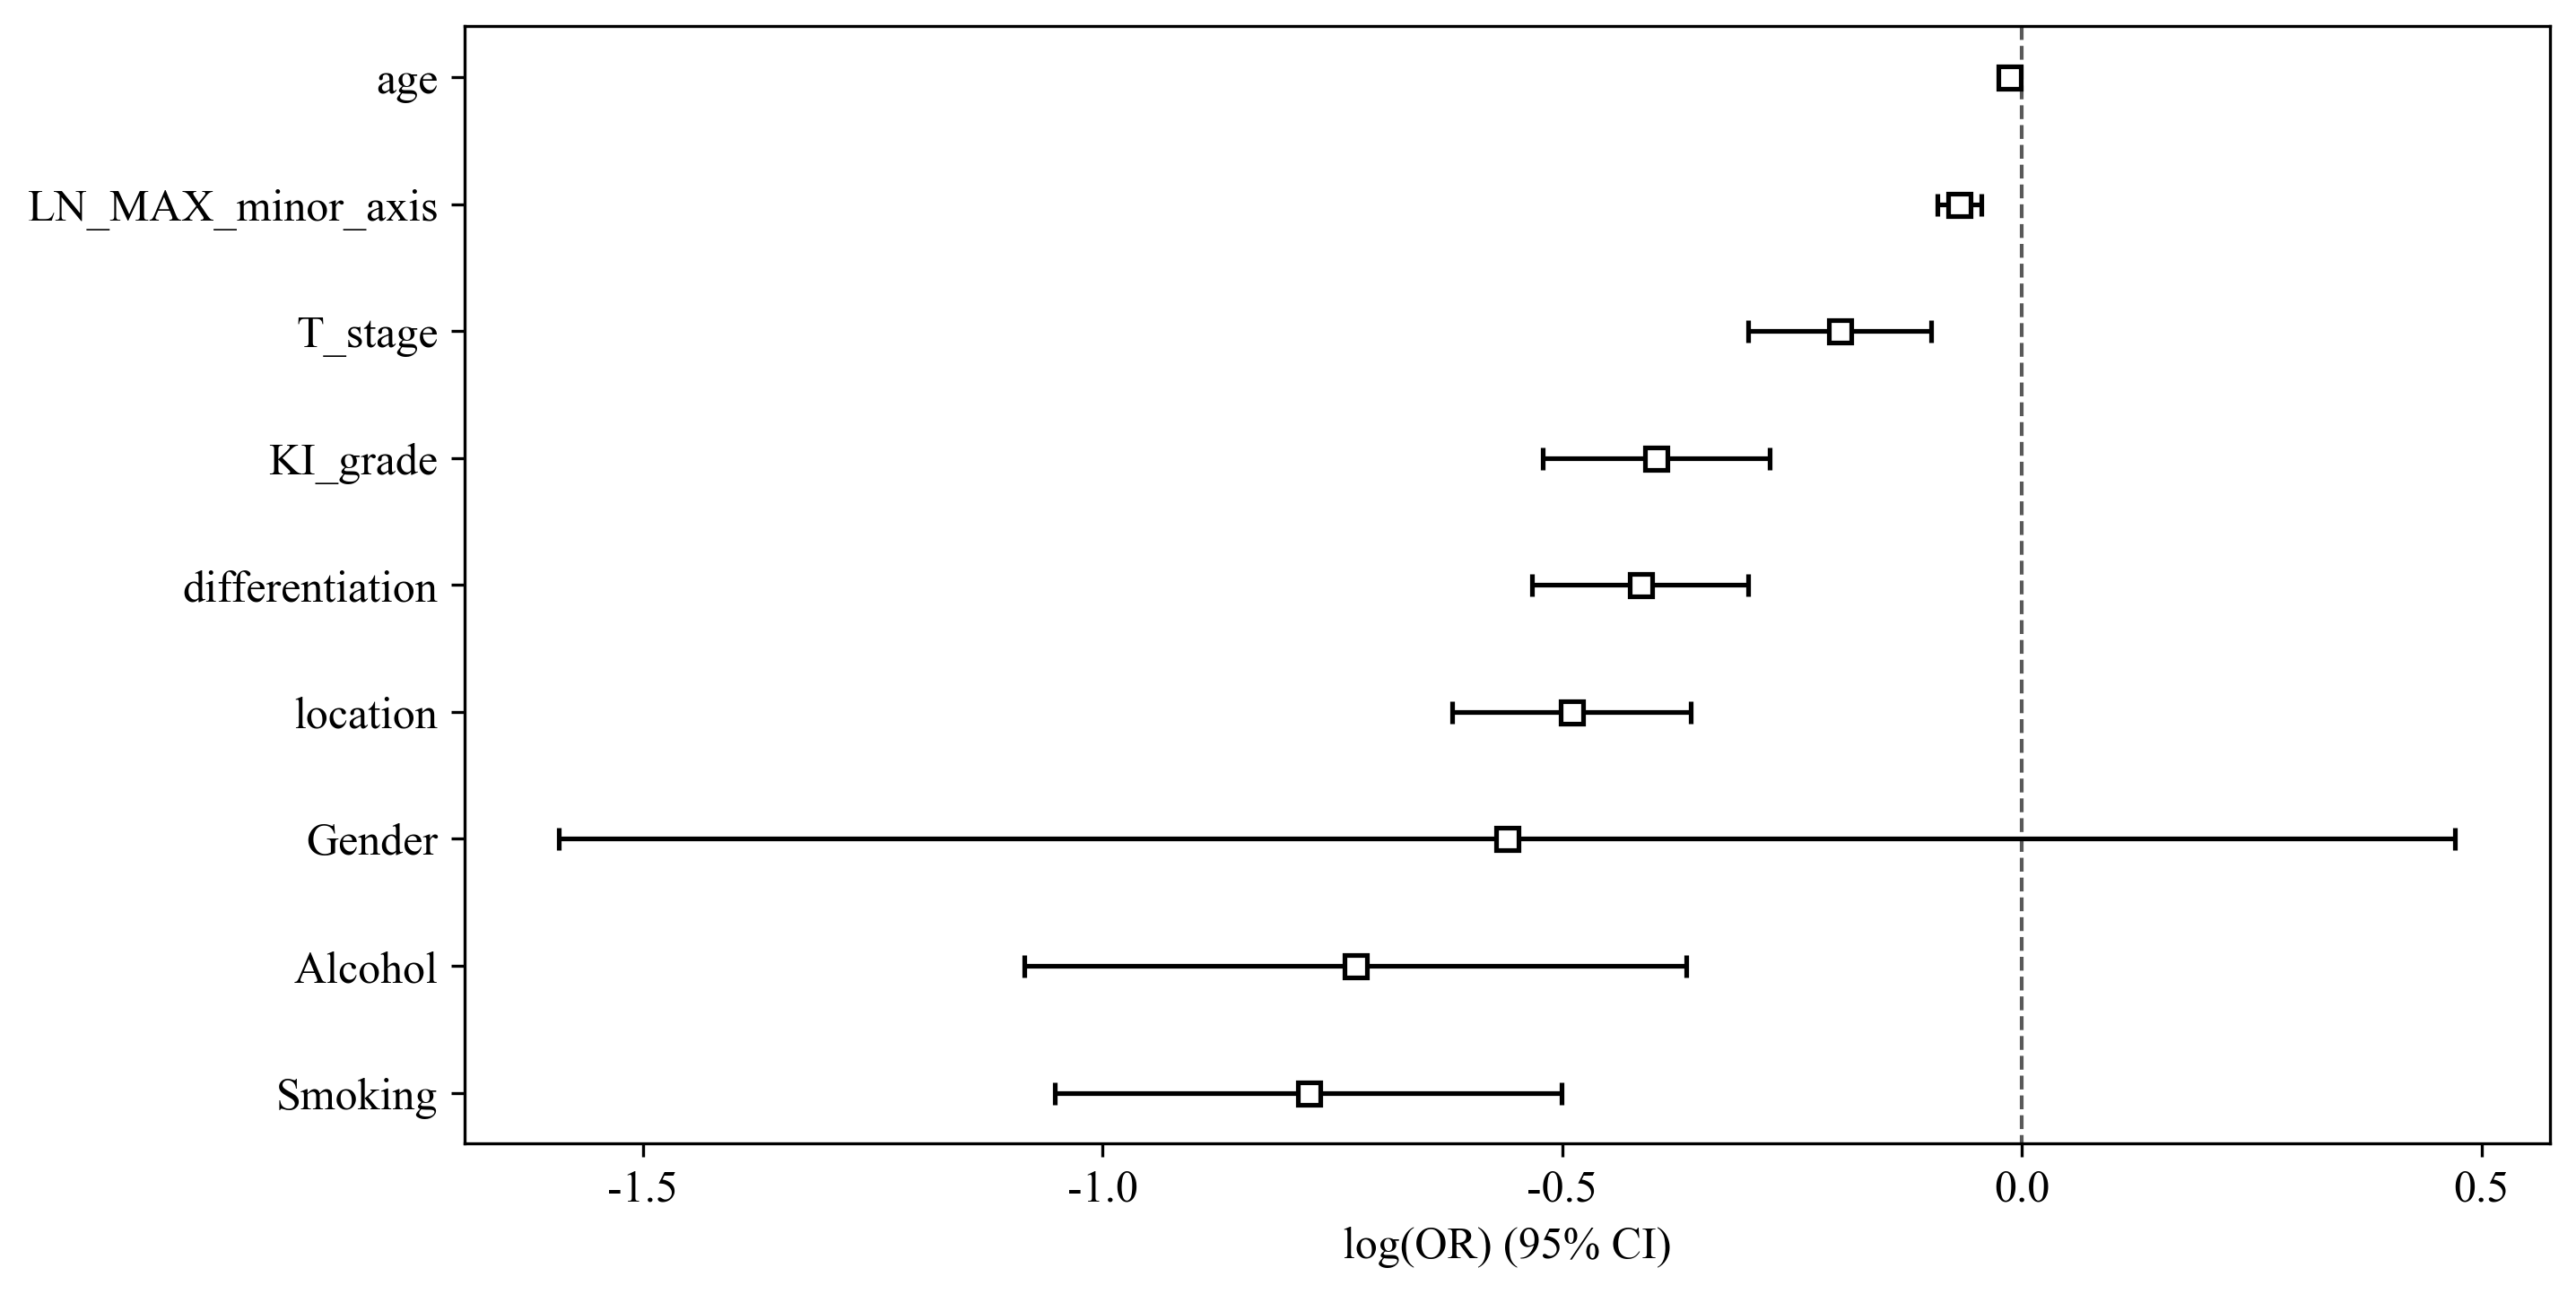

Optimization terminated successfully.
         Current function value: 0.493000
         Iterations 6


,Log(OR),lower 95%CI,upper 95%CI,OR,OR lower 95%CI,OR upper 95%CI,p_value
feature_name,,,,,,,
Smoking,0.236,-0.489,0.961,1.266,0.613,2.614,0.593
Alcohol,0.356,-0.247,0.958,1.427,0.781,2.606,0.332
location,-0.499,-0.791,-0.207,0.607,0.453,0.813,0.005
differentiation,-0.268,-0.636,0.101,0.765,0.529,1.106,0.232
KI_grade,0.196,-0.157,0.550,1.217,0.855,1.733,0.361
T_stage,0.879,0.583,1.176,2.409,1.791,3.241,0.000
LN_MAX_minor_axis,0.076,0.004,0.148,1.079,1.004,1.160,0.084
age,-0.046,-0.069,-0.024,0.955,0.933,0.976,0.001


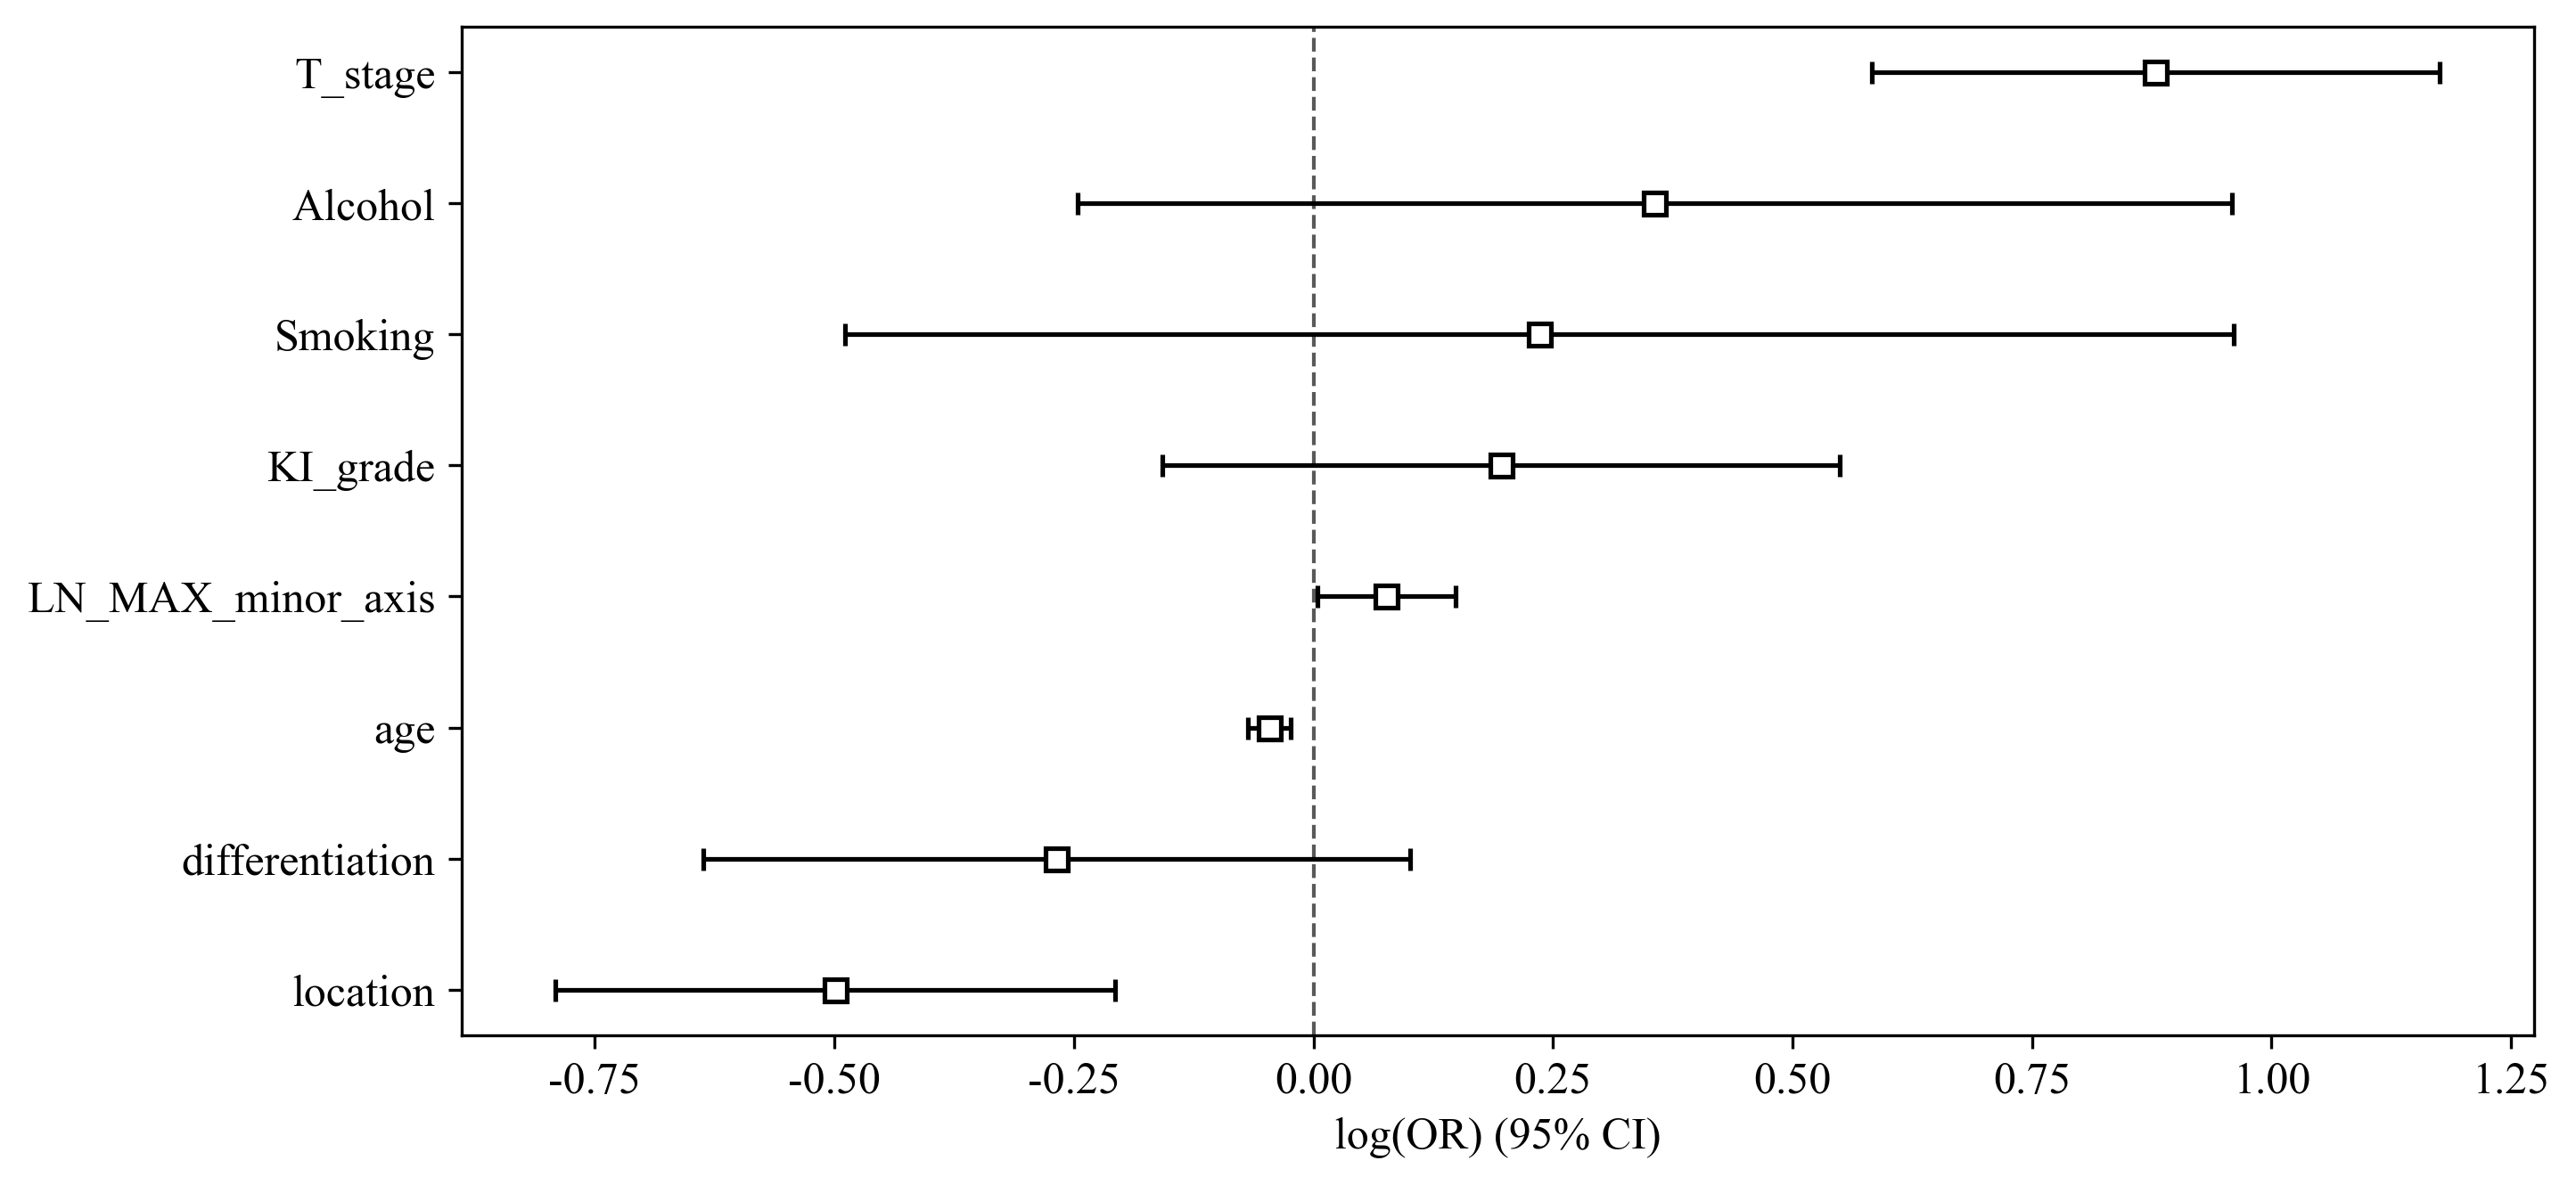

In [10]:
from onekey_algo.custom.components.comp1 import uni_multi_variable_analysis                        

uni_multi_variable_analysis(data[data['group'] == 'train'], stats_columns, save_dir='img', p_value4multi=p_value, algo='logit')

In [11]:
uni_v = pd.read_csv('img/multivariable_reg.csv')
uni_v = uni_v[uni_v['p_value'] <= 0.05]
sel_data = data[['ID'] + list(uni_v['feature_name']) + ['group', 'label']]
sel_data.to_csv('data/clinic_sel.csv', index=False)
sel_data

,ID,location,age,T_stage,group,label
0,1.nii.gz,2,54,3,train,0
1,2.nii.gz,1,67,3,train,0
2,3.nii.gz,2,67,1,train,0
3,4.nii.gz,1,62,4,train,0
4,5.nii.gz,3,73,1,train,0
5,7.nii.gz,2,70,1,train,0
6,9.nii.gz,1,58,3,train,1
7,10.nii.gz,3,53,1,train,0
8,11.nii.gz,2,75,1,train,0
9,12.nii.gz,2,55,1,train,0


In [12]:
uni = pd.read_csv('img/univariable_reg.csv')
uni = uni[[c for c in uni if ('OR' in c and 'Log' not in c) or c in ['feature_name', 'p_value']]]
multi = pd.read_csv('img/multivariable_reg.csv')
multi = multi[[c for c in uni if ('OR' in c and 'Log' not in c) or c in ['feature_name', 'p_value']]]
info = pd.merge(uni, multi, on='feature_name', how='left', suffixes=['_UNI', '_MULTI']).applymap(lambda x: '' if pd.isna(x) else x)
info.to_csv('results/unimulti.csv', index=False)
info

,feature_name,OR_UNI,OR lower 95%CI_UNI,OR upper 95%CI_UNI,p_value_UNI,OR_MULTI,OR lower 95%CI_MULTI,OR upper 95%CI_MULTI,p_value_MULTI
0,Smoking,0.460,0.349,0.606,0.000,1.266,0.613,2.614,0.593
1,Alcohol,0.484,0.338,0.694,0.001,1.427,0.781,2.606,0.332
2,Gender,0.571,0.204,1.602,0.372,,,,
3,location,0.613,0.538,0.698,0.000,0.607,0.453,0.813,0.005
4,differentiation,0.661,0.587,0.743,0.000,0.765,0.529,1.106,0.232
5,KI_grade,0.672,0.593,0.760,0.000,1.217,0.855,1.733,0.361
6,T_stage,0.820,0.742,0.906,0.001,2.409,1.791,3.241,0.0
7,LN_MAX_minor_axis,0.934,0.912,0.956,0.000,1.079,1.004,1.16,0.084
8,age,0.986,0.982,0.990,0.000,0.955,0.933,0.976,0.001
